In [1]:
!pip install -q -U torch torchvision scikit-learn pillow opencv-python-headless pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sklearn-compat 0.1.5 requires scikit-learn<1.9,>=1.2, but you have scikit-learn 1.9.1 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import os
import random
import copy
import json
import time

from pathlib import Path

import numpy as np
import pandas as pd
import cv2

from PIL import Image, ImageEnhance

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from torchvision import datasets, models

from torchvision.models import (
    EfficientNet_V2_S_Weights,
    ConvNeXt_Tiny_Weights,
    Swin_T_Weights
)

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt

In [27]:
# ============================================================
# CONFIGURACIÓN GENERAL
# ============================================================

SEED = 42

# ------------------------------------------------------------
# RUTA DEL DATASET
# ------------------------------------------------------------

DATASET_ROOT = Path(
    r"C:\Fabrizzio Gavilan\CICLO 10\EXPERIMENTO_1\orange_diseases"
)

TRAIN_DIR = DATASET_ROOT / "train"
TEST_DIR = DATASET_ROOT / "test"


# ------------------------------------------------------------
# CLASES
# ------------------------------------------------------------

# Nombres EXACTOS de las carpetas
CLASS_NAMES = [
    "blackspot",
    "canker",
    "fresh",
    "greening"
]

# Nombres para mostrar en figuras/tablas
CLASS_DISPLAY_NAMES = [
    "Blackspot",
    "Canker",
    "Fresh",
    "Greening"
]

NUM_CLASSES = len(CLASS_NAMES)


# ------------------------------------------------------------
# VALIDACIÓN
# ------------------------------------------------------------

# 15% del TRAIN original se utilizará para VALIDATION
VAL_RATIO = 0.15


# ------------------------------------------------------------
# ENTRENAMIENTO
# ------------------------------------------------------------

# Para la primera prueba en CPU
BATCH_SIZE = 8

# -------------------------
# Modo de prueba inicial
# -------------------------

TEST_RUN = True

if TEST_RUN:

    # Solo 1 época por fase
    PHASE1_EPOCHS = 1
    PHASE2_EPOCHS = 1

else:

    # Entrenamiento definitivo
    PHASE1_EPOCHS = 5
    PHASE2_EPOCHS = 25


# Learning rates
PHASE1_LR = 1e-3
PHASE2_LR = 1e-5

# Regularización
WEIGHT_DECAY = 1e-4

# Early stopping
PATIENCE = 5


# ------------------------------------------------------------
# DATA LOADER
# ------------------------------------------------------------

# Para Jupyter/Windows
NUM_WORKERS = 0


# ------------------------------------------------------------
# MODELOS
# ------------------------------------------------------------

# PRIMERA PRUEBA
MODELS_TO_RUN = [
    "ConvNeXt-Tiny"
]

# CUANDO TODO FUNCIONE, CAMBIA POR:
#
# MODELS_TO_RUN = [
#     "EfficientNetV2-S",
#     "ConvNeXt-Tiny",
#     "Swin-T"
# ]


# ------------------------------------------------------------
# DIRECTORIOS DE SALIDA
# ------------------------------------------------------------

OUTPUT_DIR = Path("outputs")

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
HISTORY_DIR = OUTPUT_DIR / "history"
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"


for folder in [
    CHECKPOINT_DIR,
    HISTORY_DIR,
    RESULTS_DIR,
    FIGURE_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# DISPOSITIVO
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Dispositivo:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

else:

    print(
        "CUDA no disponible."
    )

    print(
        "Se utilizará CPU."
    )

Dispositivo: cpu
CUDA no disponible.
Se utilizará CPU.


In [28]:
import torch
import torchvision

print(
    "PyTorch:",
    torch.__version__
)

print(
    "TorchVision:",
    torchvision.__version__
)

print(
    "CUDA disponible:",
    torch.cuda.is_available()
)

PyTorch: 2.14.0+cpu
TorchVision: 0.29.0+cpu
CUDA disponible: False


In [29]:
def seed_everything(seed=42):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

print(
    f"Seed utilizada: {SEED}"
)

Seed utilizada: 42


In [31]:
print(
    "Dataset:",
    DATASET_ROOT
)

print(
    "Train:",
    TRAIN_DIR
)

print(
    "Test:",
    TEST_DIR
)

print(
    "\nTrain existe:",
    TRAIN_DIR.exists()
)

print(
    "Test existe:",
    TEST_DIR.exists()
)


if not TRAIN_DIR.exists():

    raise FileNotFoundError(
        "\nNo se encontró la carpeta TRAIN.\n"
        f"Ruta buscada:\n{TRAIN_DIR}\n\n"
    )


if not TEST_DIR.exists():

    raise FileNotFoundError(
        "\nNo se encontró la carpeta TEST.\n"
        f"Ruta buscada:\n{TEST_DIR}\n\n"
    )

Dataset: C:\Fabrizzio Gavilan\CICLO 10\EXPERIMENTO_1\orange_diseases
Train: C:\Fabrizzio Gavilan\CICLO 10\EXPERIMENTO_1\orange_diseases\train
Test: C:\Fabrizzio Gavilan\CICLO 10\EXPERIMENTO_1\orange_diseases\test

Train existe: True
Test existe: True


In [32]:
train_full = datasets.ImageFolder(
    TRAIN_DIR
)

test_base = datasets.ImageFolder(
    TEST_DIR
)

print(
    "Clases en Train:"
)

print(
    train_full.classes
)

print(
    "\nClases en Test:"
)

print(
    test_base.classes
)

print(
    "\nNúmero de imágenes Train:",
    len(train_full)
)

print(
    "Número de imágenes Test:",
    len(test_base)
)

Clases en Train:
['blackspot', 'canker', 'fresh', 'grenning']

Clases en Test:
['blackspot', 'canker', 'fresh', 'grenning']

Número de imágenes Train: 991
Número de imágenes Test: 99


In [36]:
# ============================================================
# VERIFICACIÓN DE CLASES
# ============================================================

train_classes = [
    c.strip().lower()
    for c in train_full.classes
]

test_classes = [
    c.strip().lower()
    for c in test_base.classes
]


print("Clases Train:")
print(train_classes)

print("\nClases Test:")
print(test_classes)


if train_classes != test_classes:

    raise ValueError(
        "\nLas clases de Train y Test no coinciden.\n\n"
        f"Train: {train_classes}\n"
        f"Test: {test_classes}"
    )


# Usar las clases reales del dataset
CLASS_NAMES = train_classes

# Nombres para mostrar
CLASS_DISPLAY_NAMES = [
    "Blackspot",
    "Canker",
    "Fresh",
    "Greening"
]

NUM_CLASSES = len(CLASS_NAMES)


print(
    "\n✓ Train y Test tienen las mismas clases."
)

print(
    f"✓ Número de clases: {NUM_CLASSES}"
)

Clases Train:
['blackspot', 'canker', 'fresh', 'grenning']

Clases Test:
['blackspot', 'canker', 'fresh', 'grenning']

✓ Train y Test tienen las mismas clases.
✓ Número de clases: 4


In [37]:
train_targets = np.array(
    train_full.targets
)

train_counts = np.bincount(
    train_targets,
    minlength=NUM_CLASSES
)

train_distribution = pd.DataFrame({

    "Clase":
        CLASS_DISPLAY_NAMES,

    "Cantidad":
        train_counts

})

train_distribution[
    "Porcentaje"
] = (

    train_distribution[
        "Cantidad"
    ]
    /
    train_distribution[
        "Cantidad"
    ].sum()
    *
    100

).round(2)

train_distribution

,Clase,Cantidad,Porcentaje
0,Blackspot,184,18.57
1,Canker,179,18.06
2,Fresh,281,28.36
3,Greening,347,35.02


In [38]:
test_targets = np.array(
    test_base.targets
)

test_counts = np.bincount(
    test_targets,
    minlength=NUM_CLASSES
)

test_distribution = pd.DataFrame({

    "Clase":
        CLASS_DISPLAY_NAMES,

    "Cantidad":
        test_counts

})

test_distribution[
    "Porcentaje"
] = (

    test_distribution[
        "Cantidad"
    ]
    /
    test_distribution[
        "Cantidad"
    ].sum()
    *
    100

).round(2)

test_distribution

,Clase,Cantidad,Porcentaje
0,Blackspot,22,22.22
1,Canker,22,22.22
2,Fresh,33,33.33
3,Greening,22,22.22


In [39]:
train_indices_all = np.arange(
    len(train_full)
)

train_indices, val_indices = train_test_split(

    train_indices_all,

    test_size=VAL_RATIO,

    random_state=SEED,

    stratify=train_targets
)


print(
    "Train:",
    len(train_indices)
)

print(
    "Validation:",
    len(val_indices)
)

print(
    "Test:",
    len(test_base)
)

Train: 842
Validation: 149
Test: 99


In [40]:
def split_distribution(
    indices,
    targets,
    split_name
):

    split_targets = targets[
        indices
    ]

    counts = np.bincount(
        split_targets,
        minlength=NUM_CLASSES
    )

    return pd.DataFrame({

        "Clase":
            CLASS_DISPLAY_NAMES,

        split_name:
            counts

    })


train_dist = split_distribution(
    train_indices,
    train_targets,
    "Train"
)

val_dist = split_distribution(
    val_indices,
    train_targets,
    "Validation"
)

test_dist = pd.DataFrame({

    "Clase":
        CLASS_DISPLAY_NAMES,

    "Test":
        test_counts

})


distribution_table = (

    train_dist

    .merge(
        val_dist,
        on="Clase"
    )

    .merge(
        test_dist,
        on="Clase"
    )

)

distribution_table

,Clase,Train,Validation,Test
0,Blackspot,156,28,22
1,Canker,152,27,22
2,Fresh,239,42,33
3,Greening,295,52,22


In [41]:
def remove_shadows(image):

    img = np.array(
        image
    )

    lab = cv2.cvtColor(
        img,
        cv2.COLOR_RGB2LAB
    )

    l_channel, a_channel, b_channel = cv2.split(
        lab
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (21, 21)
    )

    background = cv2.morphologyEx(
        l_channel,
        cv2.MORPH_CLOSE,
        kernel
    )

    background = np.maximum(
        background,
        1
    )

    normalized_l = cv2.divide(
        l_channel,
        background,
        scale=255
    )

    normalized_l = cv2.normalize(
        normalized_l,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    ).astype(
        np.uint8
    )

    result_lab = cv2.merge([
        normalized_l,
        a_channel,
        b_channel
    ])

    result_rgb = cv2.cvtColor(
        result_lab,
        cv2.COLOR_LAB2RGB
    )

    return Image.fromarray(
        result_rgb
    )

In [42]:
def adjust_pixel_intensity(
    image,
    alpha=1.10
):

    img = np.array(
        image
    ).astype(
        np.float32
    )

    img *= alpha

    img = np.clip(
        img,
        0,
        255
    )

    return Image.fromarray(
        img.astype(
            np.uint8
        )
    )

In [43]:
def improve_brightness(
    image,
    factor=1.20
):

    enhancer = (
        ImageEnhance.Brightness(
            image
        )
    )

    return enhancer.enhance(
        factor
    )

In [44]:
def improve_local_contrast(
    image,
    clip_limit=2.0,
    tile_grid_size=(8, 8)
):

    img = np.array(
        image
    )

    lab = cv2.cvtColor(
        img,
        cv2.COLOR_RGB2LAB
    )

    l_channel, a_channel, b_channel = cv2.split(
        lab
    )

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid_size
    )

    enhanced_l = clahe.apply(
        l_channel
    )

    result_lab = cv2.merge([
        enhanced_l,
        a_channel,
        b_channel
    ])

    result_rgb = cv2.cvtColor(
        result_lab,
        cv2.COLOR_LAB2RGB
    )

    return Image.fromarray(
        result_rgb
    )

In [45]:
AUGMENTATION_NAMES = [

    "Shadow Removal",

    "Intensity Adjustment",

    "Brightness Enhancement",

    "Local Contrast Enhancement"

]


def apply_augmentation(
    image,
    augmentation_id
):

    if augmentation_id == 0:

        return remove_shadows(
            image
        )

    elif augmentation_id == 1:

        return adjust_pixel_intensity(
            image
        )

    elif augmentation_id == 2:

        return improve_brightness(
            image
        )

    elif augmentation_id == 3:

        return improve_local_contrast(
            image
        )

    else:

        raise ValueError(
            "augmentation_id inválido."
        )

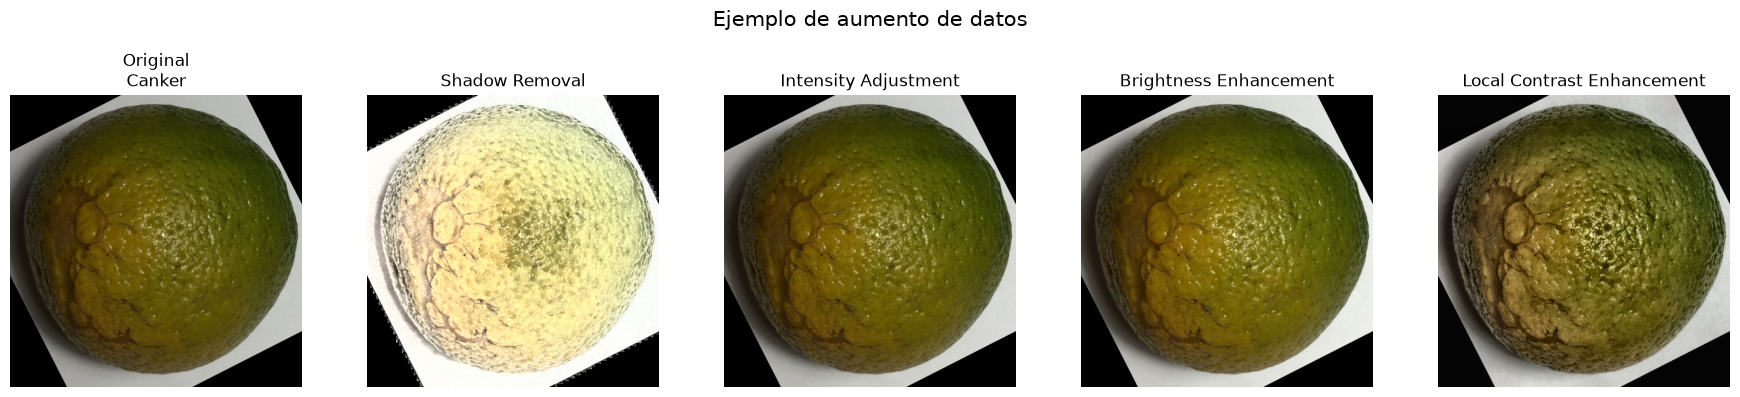

In [46]:
# ============================================================
# EJEMPLO DE DATA AUGMENTATION
# ============================================================

sample_index = train_indices[0]

image_path, label = (
    train_full.samples[
        sample_index
    ]
)

original_image = Image.open(
    image_path
).convert("RGB")


fig, axes = plt.subplots(
    1,
    5,
    figsize=(18, 4)
)


# Imagen original
axes[0].imshow(
    original_image
)

axes[0].set_title(
    f"Original\n"
    f"{CLASS_DISPLAY_NAMES[label]}"
)

axes[0].axis("off")


# Cuatro aumentos
for i in range(4):

    augmented_image = (
        apply_augmentation(
            original_image,
            i
        )
    )

    axes[i + 1].imshow(
        augmented_image
    )

    axes[i + 1].set_title(
        AUGMENTATION_NAMES[i]
    )

    axes[i + 1].axis("off")


plt.suptitle(
    "Ejemplo de aumento de datos",
    fontsize=15
)

plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.92
    ]
)

plt.show()

In [47]:
augmentation_figure_path = (
    FIGURE_DIR
    /
    "data_augmentation_example.png"
)

fig.savefig(
    augmentation_figure_path,
    dpi=300,
    bbox_inches="tight"
)

print(
    "Figura guardada en:"
)

print(
    augmentation_figure_path
)

Figura guardada en:
outputs\figures\data_augmentation_example.png


In [48]:
class AugmentedDataset(
    Dataset
):

    def __init__(
        self,
        base_dataset,
        indices,
        transform=None
    ):

        self.base_dataset = (
            base_dataset
        )

        self.indices = (
            indices
        )

        self.transform = (
            transform
        )

        self.num_augmentations = 4


    def __len__(self):

        return (
            len(self.indices)
            *
            self.num_augmentations
        )


    def __getitem__(
        self,
        idx
    ):

        base_position = (
            idx
            //
            self.num_augmentations
        )

        augmentation_id = (
            idx
            %
            self.num_augmentations
        )

        original_index = (
            self.indices[
                base_position
            ]
        )

        image_path, label = (
            self.base_dataset.samples[
                original_index
            ]
        )

        image = Image.open(
            image_path
        ).convert("RGB")


        # Aplicar una transformación
        image = apply_augmentation(
            image,
            augmentation_id
        )


        # Aplicar transformación
        # específica del modelo
        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label

In [49]:
class StandardSubset(
    Dataset
):

    def __init__(
        self,
        base_dataset,
        indices,
        transform=None
    ):

        self.base_dataset = (
            base_dataset
        )

        self.indices = (
            indices
        )

        self.transform = (
            transform
        )


    def __len__(self):

        return len(
            self.indices
        )


    def __getitem__(
        self,
        idx
    ):

        original_index = (
            self.indices[idx]
        )

        image_path, label = (
            self.base_dataset.samples[
                original_index
            ]
        )

        image = Image.open(
            image_path
        ).convert("RGB")


        # NO Data Augmentation
        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label